In [1]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner

In [2]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

In [3]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00  3.71049551e-17]
 [ 1.34841040e-17 -4.75068849e-01]]
[[[[ 6.74755927e-01 -3.75785642e-17]
   [-5.45047948e-17  1.81210462e-01]]

  [[-5.45047948e-17  1.81210462e-01]
   [ 6.63711401e-01  4.06319362e-16]]]


 [[[-3.75785642e-17  6.63711401e-01]
   [ 1.81210462e-01  5.57982113e-16]]

  [[ 1.81210462e-01  5.57982113e-16]
   [ 4.06319362e-16  6.97651504e-01]]]]
0.7151043390810812


In [4]:
from openfermion import InteractionOperator
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)

In [5]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nstates = 4
energy, ci = cisolver.kernel()
print("FCI energy:", energy)

FCI energy: [-1.13728383 -0.53077336 -0.16835243  0.48314267]


In [6]:
from pyscf import fci
from pyscf.fci import cistring, spin_op

cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nroots = 4

energies, ci = cisolver.kernel()

ncas = cisolver.norb
nelec = cisolver.nelec

na, nb = nelec

# Alpha and beta determinants
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (alpha beta alpha beta ...)."""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]

    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))

    return ''.join(inter)[::-1]


print('\namplitudes FCI')

tol_ampl = 0.01

for state, ci_state in enumerate(ci):

    # Compute S^2 and spin multiplicity
    s2, multiplicity = spin_op.spin_square(
        ci_state,
        ncas,
        nelec
    )

    # Recover S from S(S+1)
    spin = (-1 + (1 + 4 * s2)**0.5) / 2

    print(
        f'\nState {state}   '
        f'Energy = {energies[state]:+.10f}   '
        f'<S^2> = {s2:.6f}   '
        f'S = {spin:.1f}   '
        f'2S+1 = {multiplicity:.1f}'
    )

    for i, a in enumerate(alpha_det):
        for j, b in enumerate(beta_det):

            amp = ci_state[i, j]

            if amp**2 > tol_ampl:
                cfg = interleave_bits(a, b, ncas)
                print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f})")


amplitudes FCI

State 0   Energy = -1.1372838345   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
1100   +0.993647  (0.987334)
0011   -0.112544  (0.012666)

State 1   Energy = -0.5307733570   <S^2> = 2.000000   S = 1.0   2S+1 = 3.0
0110   +0.707107  (0.500000)
1001   -0.707107  (0.500000)

State 2   Energy = -0.1683524330   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
0110   -0.707107  (0.500000)
1001   -0.707107  (0.500000)

State 3   Energy = +0.4831426731   <S^2> = 0.000000   S = 0.0   2S+1 = 1.0
1100   +0.112544  (0.012666)
0011   +0.993647  (0.987334)


In [7]:
from itertools import product
from openfermion import FermionOperator

#first singlet
pool = []
for i in range(2):
    for a in range(2, 4):
        pool.append(FermionOperator(f'{a}^ {i}'))

for i in range(2):
    for j in range(i, 2):
        for a in range(2, 4):
            for b in range(a, 4):
                pool.append(FermionOperator(f'{b}^ {a}^ {j} {i}'))

for op in pool:
    print(op)

1.0 [2^ 0]
1.0 [3^ 0]
1.0 [2^ 1]
1.0 [3^ 1]
1.0 [2^ 2^ 0 0]
1.0 [3^ 2^ 0 0]
1.0 [3^ 3^ 0 0]
1.0 [2^ 2^ 1 0]
1.0 [3^ 2^ 1 0]
1.0 [3^ 3^ 1 0]
1.0 [2^ 2^ 1 1]
1.0 [3^ 2^ 1 1]
1.0 [3^ 3^ 1 1]


In [8]:
from openfermion import FermionOperator

# triplet (ms=0)
pool_2 = []
for i in [1, 2]:
    for a in range(4):
        pool_2.append(FermionOperator(f'{a}^ {i}'))

for i in [1, 2]:
    for j in [1, 2]:
        if i >= j:
            continue
        for a in range(4):
            for b in range(a+1, 4):
                pool_2.append(FermionOperator(f'{b}^ {a}^ {j} {i}'))

for op in pool_2:
    print(op)

pool = pool_2

1.0 [0^ 1]
1.0 [1^ 1]
1.0 [2^ 1]
1.0 [3^ 1]
1.0 [0^ 2]
1.0 [1^ 2]
1.0 [2^ 2]
1.0 [3^ 2]
1.0 [1^ 0^ 2 1]
1.0 [2^ 0^ 2 1]
1.0 [3^ 0^ 2 1]
1.0 [2^ 1^ 2 1]
1.0 [3^ 1^ 2 1]
1.0 [3^ 2^ 2 1]


In [9]:
from openfermion import FermionOperator

# triplet (ms=1/-1)
pool_3 = []
for i in range(2):
    for a in range(i, 2):
        pool_3.append(FermionOperator(f'{2*a}^ {2*i}'))
        pool_3.append(FermionOperator(f'{2*a+1}^ {2*i+1}'))

for i in range(2):
    for j in range(j, 2):
        for a in range(2):
            for b in range(a, 2):
                pool_3.append(FermionOperator(f'{2*b}^ {2*a}^ {2*j} {2*i}'))
                pool_3.append(FermionOperator(f'{2*b+1}^ {2*a+1}^ {2*j+1} {2*i+1}'))
                pool_3.append(FermionOperator(f'{2*b}^ {2*a+1}^ {2*j} {2*i+1}'))
                pool_3.append(FermionOperator(f'{2*b+1}^ {2*a}^ {2*j+1} {2*i}'))

for op in pool_3:
    print(op)

#pool = pool_3

1.0 [0^ 0]
1.0 [1^ 1]
1.0 [2^ 0]
1.0 [3^ 1]
1.0 [2^ 2]
1.0 [3^ 3]


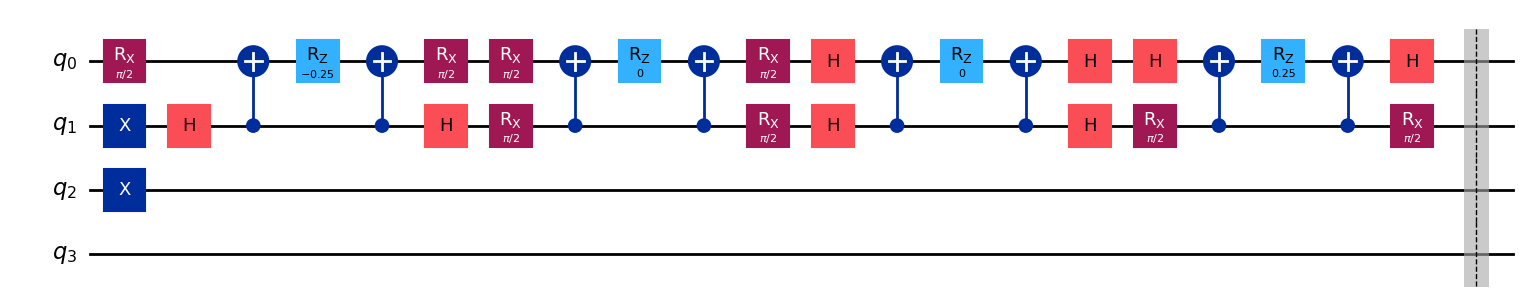

In [10]:
from qiskit import QuantumCircuit
def get_circuit(operators):

    # Build the ansatz
    qc = QuantumCircuit(4)

    # reference
    qc.x(1)
    qc.x(2)

    for f_op in operators:
        qubit_op = jordan_wigner(f_op)

        # print(op)
        for pauli_string, coef in qubit_op.terms.items():

            for qubit, pauli in pauli_string:
                if pauli == 'X':
                    qc.h(qubit)
                elif pauli == 'Y':
                    qc.rx(np.pi / 2, [qubit])

            for qubit, pauli in pauli_string[1:]:
                qc.cx(qubit, pauli_string[0][0])

            if len(pauli_string) > 0:
                qc.rz(coef.imag, pauli_string[0][0])

            for qubit, pauli in pauli_string[1:]:
                qc.cx(qubit, pauli_string[0][0])

            for qubit, pauli in pauli_string:
                if pauli == 'X':
                    qc.h(qubit)
                elif pauli == 'Y':
                    qc.rx(np.pi / 2, [qubit])

        qc.barrier()

    #qc.draw('mpl')
    return qc

get_circuit(pool[:1]).draw('mpl')

Gradients

In [17]:
from qiskit.primitives import StatevectorSampler

def cost_function(operators, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = get_circuit(operators)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [18]:
from openfermion import jordan_wigner
H_qubit = jordan_wigner(hamiltonian)

In [19]:
for op in pool:
    qubit_op = jordan_wigner(op)
    commutator = qubit_op * H_qubit - H_qubit * qubit_op
    cost = abs(cost_function([], commutator))
    print('{:.5f} {}'.format(cost, op))


0.00038 1.0 [0^ 1]
0.00000 1.0 [1^ 1]
0.00083 1.0 [2^ 1]
0.00048 1.0 [3^ 1]
0.00045 1.0 [0^ 2]
0.00007 1.0 [1^ 2]
0.00000 1.0 [2^ 2]
0.00041 1.0 [3^ 2]
0.00053 1.0 [1^ 0^ 2 1]
0.00044 1.0 [2^ 0^ 2 1]
0.18121 1.0 [3^ 0^ 2 1]
0.00000 1.0 [2^ 1^ 2 1]
0.00018 1.0 [3^ 1^ 2 1]
0.00041 1.0 [3^ 2^ 2 1]


In [20]:
from scipy.optimize import minimize

def combine(parameters, operators):
    return [c * op for c, op in zip(parameters, operators)]

operators = []
parameters = []
for step in range(3):

    i_max = 0
    grad_max = 0
    cost_vector = []

    print('gradients')
    for i, op in enumerate(pool):
        qubit_op = jordan_wigner(op)
        commutator = qubit_op * H_qubit - H_qubit * qubit_op
        cost = abs(cost_function(combine(parameters, operators), commutator))
        cost_vector.append(cost)
        print('{:.5f} {}'.format(cost, op))

        if cost > grad_max:
            grad_max = cost
            i_max = i

    # convergence criteria
    grad_norm = np.linalg.norm(cost_vector)
    print('gradient norm', grad_norm)
    if grad_norm < 1e-4:
        print('converged')
        break

    operators.append(pool[i_max])
    print('selected: ', pool[i_max])

    def cost_adapt(trial_params, H_qubit):
        return cost_function(combine(trial_params, operators), H_qubit)

    # Initial parameters
    parameters.append(0)


    # Optimization
    print('minimization')
    result = minimize(
        cost_adapt,
        parameters,
        args=(H_qubit),
        method="COBYLA",
        options={"maxiter": 200,
                 "disp": True,
                 "rhobeg": 0.5,
                 "tol": 1e-4,
        },
    )

    print("Optimal parameters:", result.x)
    print("Minimum energy:", result.fun)

    parameters = result.x.tolist()



gradients
0.00003 1.0 [0^ 1]
0.00000 1.0 [1^ 1]
0.00026 1.0 [2^ 1]
0.00159 1.0 [3^ 1]
0.00004 1.0 [0^ 2]
0.00049 1.0 [1^ 2]
0.00000 1.0 [2^ 2]
0.00015 1.0 [3^ 2]
0.00024 1.0 [1^ 0^ 2 1]
0.00016 1.0 [2^ 0^ 2 1]
0.18121 1.0 [3^ 0^ 2 1]
0.00000 1.0 [2^ 1^ 2 1]
0.00032 1.0 [3^ 1^ 2 1]
0.00014 1.0 [3^ 2^ 2 1]
gradient norm 0.1812189101795314
selected:  1.0 [3^ 0^ 2 1]
minimization
Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 30   Least value of F = -0.531653613150809
The corresponding X is: [6.625625]

Optimal parameters: [6.625625]
Minimum energy: -0.531653613150809
gradients
0.00033 1.0 [0^ 1]
0.00000 1.0 [1^ 1]
0.00071 1.0 [2^ 1]
0.00044 1.0 [3^ 1]
0.00041 1.0 [0^ 2]
0.00058 1.0 [1^ 2]
0.00000 1.0 [2^ 2]
0.00011 1.0 [3^ 2]
0.00122 1.0 [1^ 0^ 2 1]
0.00012 1.0 [2^ 0^ 2 1]
0.01557 1.0 [3^ 0^ 2 1]
0.00000 1.0 [2^ 1^ 2 1]
0.00006 1.0 [3^ 1^ 2 1]
0.00051 1.0 [3^ 2^ 2 1]
gradient norm 0.015671655853787242
selected:  1.0 [3^ 0^ 2 1]
mini

In [15]:
from openfermion import FermionOperator, jordan_wigner


def sz_operator(n_spatial_orbitals):

    Sz = FermionOperator()

    for p in range(n_spatial_orbitals):

        alpha = 2 * p
        beta = 2 * p + 1

        Sz += 0.5 * FermionOperator(f'{alpha}^ {alpha}')
        Sz -= 0.5 * FermionOperator(f'{beta}^ {beta}')

    return jordan_wigner(Sz)



def s2_operator(n_spatial_orbitals):

    # Build S+ and S- in second quantization
    S_plus = FermionOperator()
    S_minus = FermionOperator()

    for p in range(n_spatial_orbitals):

        alpha = 2 * p
        beta = 2 * p + 1

        S_plus += FermionOperator(f'{alpha}^ {beta}')
        S_minus += FermionOperator(f'{beta}^ {alpha}')

    # Jordan-Wigner transformation
    S_plus = jordan_wigner(S_plus)
    S_minus = jordan_wigner(S_minus)

    # Sz
    Sz = sz_operator(n_spatial_orbitals)

    # S^2 = Sz^2 + 1/2 (S+ S- + S- S+)
    S2 = Sz * Sz + 0.5 * (S_plus * S_minus + S_minus * S_plus)

    return S2

In [16]:
print('Sz: {:.5f}'.format(cost_function(combine(parameters, operators), H_qubit=sz_operator(2))))
print('S2: {:.5f}'.format(cost_function(combine(parameters, operators), H_qubit=s2_operator(2))))

Sz: -0.00088
S2: 1.99968


- change the algorithm (pool initial state) to optimize the first triplet

- Calcular el singlet (ground state)
- Calcular el triplet (ms=0)
- Calcular el triplet (ms=1/-1)